# 01 — Write a network by hand, then read one trained by RL

**References · Weight-Space Programming** · ~15 min · CPU only · [![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/zenocode-org/ai-masterclass/blob/main/en/references/01_weight_space_programming/01_write_and_read_a_policy.ipynb)

In the post, Astra **writes** game-playing networks from all-zero weights (Experiment 5), **reads** a trained policy to tell which game it plays (Experiment 1), and **fixes** a failing policy by editing its weights (Experiment 4). We do all three on a game small enough to hold in your head.

**By the end you will be able to:**
1. Write the weights of a working policy network **by hand**, with no training.
2. Train the same kind of network with reinforcement learning and **read** its first layer as images.
3. Show that the trained network found the **same algorithm** as your hand-written one.
4. **Repair** a broken network with a weight edit, without retraining.

**Plan:**
1. The game: *Catch*
2. Writing a 2-neuron policy by hand
3. Training a 200→32→32→3 policy with REINFORCE
4. Reading the trained weights
5. Fixing a broken network by editing weights
6. Summary, questions, exercises

In [1]:
# On Google Colab: fetch the course repo (wsp.py lives next to this notebook).
# Locally, this cell does nothing.
import os, sys
if "google.colab" in sys.modules and not os.path.exists("wsp.py"):
    if not os.path.exists("ai-masterclass"):
        !git clone -q --depth 1 https://github.com/zenocode-org/ai-masterclass
    %cd ai-masterclass/en/references/01_weight_space_programming

In [2]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

import wsp  # wsp.py, next to this notebook
torch.manual_seed(0)
print("PyTorch", torch.__version__)

PyTorch 2.15.0+cu132


## 1. The game: *Catch*

A ball appears in a random column of the top row of a 10×10 grid and falls one row per step. A one-cell paddle sits on the bottom row. At each step the policy picks **left, stay or right**. After 9 steps the ball reaches the bottom row: it is caught if it is in the paddle's column.

The observation is the same format as MinAtar (Experiment 5): one 10×10 grid **per object type** (channel 0 = ball, channel 1 = paddle), flattened to **200 numbers**, all 0 except two 1s.

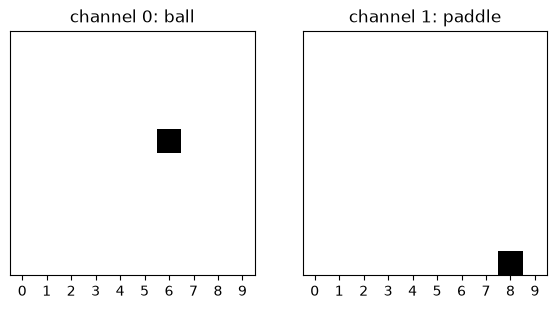

ball column: 6 | paddle column: 8
observation = 200 numbers, of which 2 are 1


In [3]:
g = torch.Generator().manual_seed(3)
s = wsp.reset(1, g)
for _ in range(4):
    wsp.step(s, torch.tensor([1]))   # stay, let the ball fall a bit
obs = wsp.observe(s).view(2, wsp.W, wsp.W)

fig, axes = plt.subplots(1, 2, figsize=(6, 3))
for ax, ch, name in zip(axes, obs, ["channel 0: ball", "channel 1: paddle"]):
    ax.imshow(ch, cmap="Greys", vmin=0, vmax=1)
    ax.set_title(name); ax.set_xticks(range(10)); ax.set_yticks([])
plt.tight_layout(); plt.show()
print("ball column:", s["bx"].item(), "| paddle column:", s["px"].item())
print("observation = 200 numbers, of which", int(wsp.observe(s).sum()), "are 1")

In [4]:
random_policy = lambda o: torch.zeros(o.shape[0], 3)      # equal logits = uniform random actions
print(f"random policy catches {wsp.play(random_policy, greedy=False):.1%} of balls")

random policy catches 9.8% of balls


## 2. Writing the policy by hand

Before training anything, think like a programmer. What does the policy need to compute? Only the **sign** of

$$d = \text{ball column} - \text{paddle column}.$$

If $d>0$, go right. If $d<0$, go left. If $d=0$, stay.

**Step 1: get the columns as numbers.** The input is one-hot. If every ball cell in column $c$ has weight $c$, the dot product of those weights with the input *is* the ball's column. Same trick for the paddle.

**Step 2: split the sign into two ReLU neurons.**

$$h_0 = \text{ReLU}(b_x - p_x) \quad(\text{"ball is to the right"}),\qquad h_1 = \text{ReLU}(p_x - b_x)\quad(\text{"ball is to the left"})$$

**Step 3: turn them into action logits.** `right = 10·h0`, `left = 10·h1`, `stay = 5` (a constant bias). When $d=0$ both neurons are 0 and *stay* wins. When $|d|\ge 1$ the matching side gets at least 10 > 5.

That is a **200 → 2 → 3** network with every weight chosen on purpose. Here it is, starting from all zeros as in Experiment 5:

In [5]:
net = nn.Sequential(nn.Linear(2 * wsp.W * wsp.W, 2), nn.ReLU(), nn.Linear(2, 3))
with torch.no_grad():
    for p in net.parameters():
        p.zero_()                                      # start from nothing
    col = torch.arange(wsp.W).float()                  # 0, 1, ..., 9
    ball = col.repeat(wsp.W)                           # ball cell (row r, col c) gets weight c
    paddle = torch.zeros(wsp.W, wsp.W); paddle[-1] = col
    paddle = paddle.view(-1)                           # paddle cell (bottom row, col c) gets weight c
    net[0].weight[0] = torch.cat([ball, -paddle])      # h0 = relu(bx - px)
    net[0].weight[1] = torch.cat([-ball, paddle])      # h1 = relu(px - bx)
    net[2].weight[:] = torch.tensor([[0., 10.],        # left  = 10*h1
                                     [0.,  0.],        # stay  = 5 (bias)
                                     [10., 0.]])       # right = 10*h0
    net[2].bias[:] = torch.tensor([0., 5., 0.])

print(f"hand-written policy catches {wsp.play(net):.1%} of balls")
print("non-zero weights:", sum(int((p != 0).sum()) for p in net.parameters()), "out of",
      sum(p.numel() for p in net.parameters()))

hand-written policy catches 100.0% of balls
non-zero weights: 201 out of 411


**100%, with zero training.** This is weight-space programming in miniature: we wrote the program directly in the weights.

Let's *look* at the first layer. Each row of `net[0].weight` has 200 numbers. Reshaped to `(2, 10, 10)`, it shows what the neuron "looks at" in each channel. Keep this picture in mind: we will compare it with a trained network.

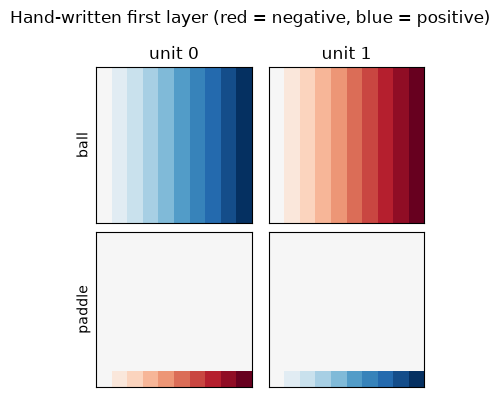

In [6]:
def show_rows(weight, units, title):
    w = weight.detach().view(-1, 2, wsp.W, wsp.W)
    fig, axes = plt.subplots(2, len(units), figsize=(1.9 * len(units), 4), squeeze=False)
    for k, u in enumerate(units):
        lim = w[u].abs().max().item()
        for ch in range(2):
            ax = axes[ch, k]
            ax.imshow(w[u, ch], cmap="RdBu", vmin=-lim, vmax=lim)
            ax.set_xticks([]); ax.set_yticks([])
            if k == 0: ax.set_ylabel(["ball", "paddle"][ch])
        axes[0, k].set_title(f"unit {u}")
    fig.suptitle(title); plt.tight_layout(); plt.show()

show_rows(net[0].weight, [0, 1], "Hand-written first layer (red = negative, blue = positive)")

Read it like Astra would: neuron 0's ball weights grow from left to right (blue on the right), and its paddle weights do the opposite, but **only on the bottom row**. "Ball to the right of the paddle" in a picture.

## 3. Training a policy with reinforcement learning

Now let gradient descent write the weights. Same input, a bigger network (200 → 32 → 32 → 3, tanh, like Experiment 1), trained with **REINFORCE**, the simplest policy-gradient method. (The paper uses PPO, a more stable relative.)

The rule fits in one line: for each episode, push up the log-probability of the actions taken, in proportion to how much better than average the episode ended (+1 for a catch, −1 for a miss).

trained policy catches 97.9% of balls


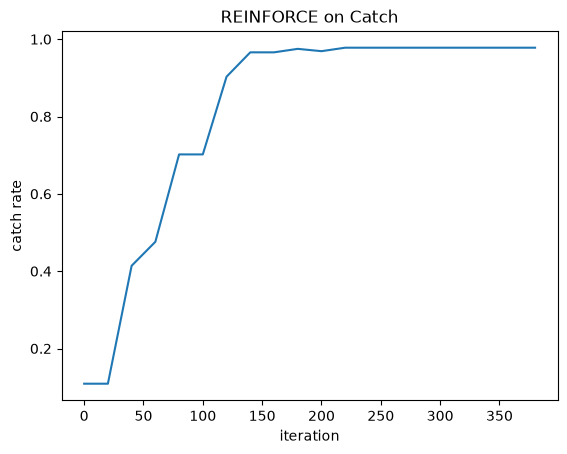

In [7]:
torch.manual_seed(0)
policy = nn.Sequential(nn.Linear(200, 32), nn.Tanh(),
                       nn.Linear(32, 32), nn.Tanh(),
                       nn.Linear(32, 3))
opt = torch.optim.Adam(policy.parameters(), lr=3e-3)
init_first_layer = policy[0].weight.detach().clone()   # kept to compare later

history = []
for it in range(400):
    s = wsp.reset(256)
    logps = []
    for _ in range(wsp.W - 1):
        dist = torch.distributions.Categorical(logits=policy(wsp.observe(s)))
        a = dist.sample()
        logps.append(dist.log_prob(a))
        wsp.step(s, a)
    reward = (s["px"] == s["bx"]).float() * 2 - 1          # +1 caught, -1 missed
    advantage = reward - reward.mean()
    loss = -(torch.stack(logps).sum(0) * advantage).mean()
    opt.zero_grad(); loss.backward(); opt.step()
    if it % 20 == 0:
        history.append((it, wsp.play(policy, batch=1000)))

print(f"trained policy catches {wsp.play(policy):.1%} of balls")
plt.plot(*zip(*history)); plt.xlabel("iteration"); plt.ylabel("catch rate"); plt.title("REINFORCE on Catch"); plt.show()

## 4. Reading the trained weights

Imagine someone hands you these 7,523 numbers and asks *"what game is this?"* (Experiment 1). Start with the first layer, displayed exactly like the hand-written one.

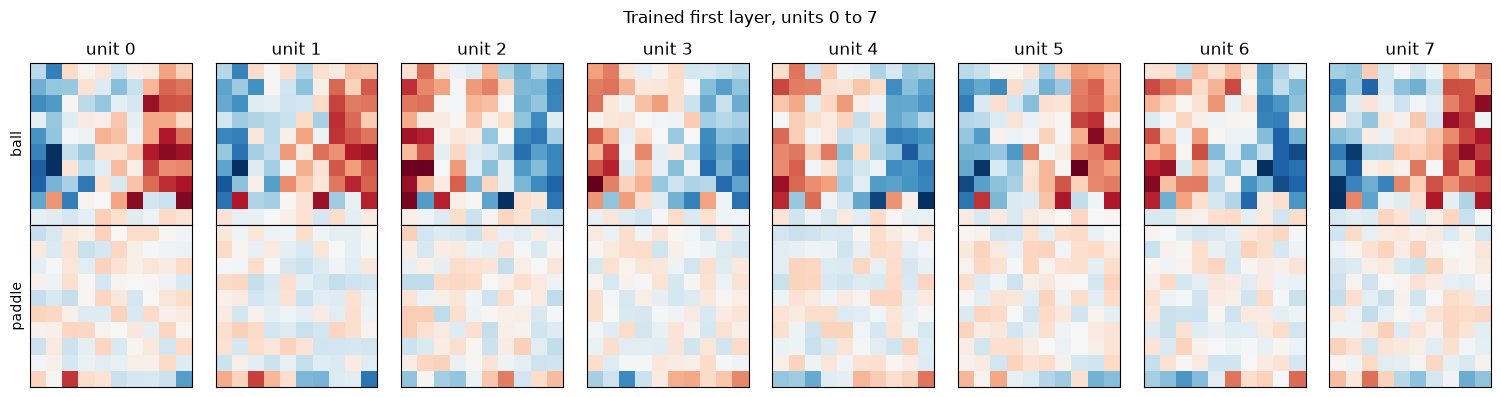

In [8]:
show_rows(policy[0].weight, range(8), "Trained first layer, units 0 to 7")

Three things are visible without running the network:

1. **Ball channel: stripes are vertical.** The weights change from column to column, but hardly from row to row. The network cares *which column* the ball is in, not how high it is.
2. **Paddle channel: only the bottom row is structured.** The other 90 paddle weights look like faint noise. Why? The paddle is never anywhere else, so those inputs are always 0 and **never receive a gradient**. They keep their random initial values. *Lesson for reading weights: untouched weights are leftover initialization, not signal.* We can check that directly:
3. **The two channels mirror each other.** Where the ball weights are blue, the paddle weights tend to be red. That is our `bx − px`.

In [9]:
w = policy[0].weight.detach().view(32, 2, wsp.W, wsp.W)
w0 = init_first_layer.view(32, 2, wsp.W, wsp.W)
moved_unused = (w[:, 1, :-1] - w0[:, 1, :-1]).abs().max().item()
moved_bottom = (w[:, 1, -1] - w0[:, 1, -1]).abs().mean().item()
print(f"paddle weights outside the bottom row moved by at most {moved_unused:.1e} during training")
print(f"paddle weights on the bottom row moved by {moved_bottom:.3f} on average")

paddle weights outside the bottom row moved by at most 0.0e+00 during training
paddle weights on the bottom row moved by 0.086 on average


Point 3 can be measured too. For each hidden unit, build its **ball profile** (the ball weights averaged over rows → 10 numbers, one per column) and its **paddle profile** (the bottom row → 10 numbers). If the unit computes something like `bx − px`, the ball profile should look like the **negative** of the paddle profile.

correlation(ball profile, -paddle profile) per unit:
[0.66 0.73 0.54 0.77 0.87 0.66 0.67 0.73 0.74 0.61 0.89 0.47 0.79 0.83
 0.79 0.69 0.8  0.7  0.75 0.8  0.74 0.86 0.81 0.74 0.83 0.57 0.67 0.54
 0.7  0.75 0.71 0.82]
31 of 32 units are 'ball vs paddle' comparators


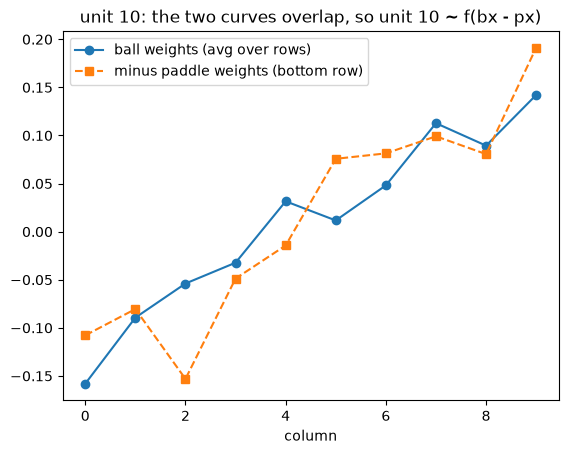

In [10]:
ball_profile = w[:, 0].mean(dim=1)        # (32, 10)
paddle_profile = w[:, 1, -1]              # (32, 10)
corr = torch.tensor([torch.corrcoef(torch.stack([ball_profile[i], -paddle_profile[i]]))[0, 1]
                     for i in range(32)])
print("correlation(ball profile, -paddle profile) per unit:")
print(corr.numpy().round(2))
print(f"{int((corr > 0.5).sum())} of 32 units are 'ball vs paddle' comparators")

i = int(corr.argmax())
plt.plot(ball_profile[i], "o-", label="ball weights (avg over rows)")
plt.plot(-paddle_profile[i], "s--", label="minus paddle weights (bottom row)")
plt.xlabel("column"); plt.title(f"unit {i}: the two curves overlap, so unit {i} ~ f(bx - px)"); plt.legend(); plt.show()

Almost every unit is a **comparator between the ball's column and the paddle's column**: the same algorithm we wrote by hand, spread over 32 noisy units instead of 2 clean ones. The optimizer did not find a cleverer program. It found ours, written less legibly.

This is why reading weights can work at all: trained networks often implement simple algorithms, and the weights show it once you know what each matrix's rows and columns mean.

## 5. Fixing a broken network by editing weights

Experiment 4 gives Astra a policy that fails and asks it to repair the weights directly. Here is our version. A hardware bug **mirrors the camera**: the network now sees the grid flipped left to right, but its actions still act on the real world.

In [11]:
def mirrored(net):
    "The same network, but it sees a left-right flipped observation."
    return lambda o: net(o.view(-1, 2, wsp.W, wsp.W).flip(-1).reshape(-1, 200))

print(f"trained policy, mirrored camera: {wsp.play(mirrored(policy)):.1%}")

trained policy, mirrored camera: 0.0%


It now moves **away** from the ball every time. Retraining would fix it, but we understand the weights, so two different one-line edits will do.

**Fix A: rewire the input.** Each first-layer weight is tied to one grid cell. If the camera flips the cells, flip the weights the same way, and every dot product is back to its old value.

**Fix B: rewire the output.** The network now computes the decision for the mirrored world, so its "left" really means "right". Swap rows 0 and 2 of the output layer.

In [12]:
import copy

fixed_a = copy.deepcopy(policy)
with torch.no_grad():
    w1 = fixed_a[0].weight.view(32, 2, wsp.W, wsp.W)
    fixed_a[0].weight.copy_(w1.flip(-1).reshape(32, 200))       # flip input weights left-right

fixed_b = copy.deepcopy(policy)
with torch.no_grad():
    fixed_b[4].weight.copy_(fixed_b[4].weight[[2, 1, 0]])       # swap "left" and "right" rows
    fixed_b[4].bias.copy_(fixed_b[4].bias[[2, 1, 0]])

print(f"fix A (input rewiring) : {wsp.play(mirrored(fixed_a)):.1%}")
print(f"fix B (output rewiring): {wsp.play(mirrored(fixed_b)):.1%}")

fix A (input rewiring) : 97.9%
fix B (output rewiring): 97.9%


Both repairs work and neither needed a single gradient step. Fix A rearranges the 6,400 first-layer weights. Fix B moves 64 weights and 2 biases. **When you know what a matrix means, the edit is obvious.** That is the whole bet of the paper, applied at a scale where you can check every step.

---
## 6. Summary

- A first-layer **row** is a template over the input. Reshape it to the input's shape and you can see what a unit detects.
- **Weights that never receive gradient keep their initial values.** A reader has to separate signal from leftover noise.
- A trained network can implement the **same algorithm** as a hand-written one, just spread over more units.
- Once a weight's role is known, an edit can **repair** behavior without training (Experiment 4), and an algorithm can be **written** directly (Experiment 5).

### Check your understanding
1. Why does `stay` need a bias of 5 and not 0 in the hand-written network?
2. In the trained network, why are the ball stripes vertical and not horizontal?
3. Fix B swaps rows of the *last* layer. Why does it also need to swap the bias?
4. Experiment 1's network had a 500-input first layer (5 channels × 10 × 10). Which channel's weights would you look at first to tell Breakout from Freeway, and what would you expect to see?

### Exercises
- **Make it move-aware.** Change the game so the ball also drifts one column left or right per step (bouncing off the walls). The observation needs 2 frames (300 inputs). Can you still write a policy by hand? *Hint:* Experiment 5's Breakout network "computes where the ball would land" in its first layer.
- **Lazy policy.** Edit *one* weight of the hand-written network so that it only moves when the ball is at least 2 columns away. What is its catch rate?
- **Sparsity.** Train with an L1 penalty on the first layer. Does the network become as readable as the hand-written one?

### References
- Experiment 1 (which game), 4 (fix a car), 5 (write from scratch) in the [post](https://rikiyat.github.io/blog/weight-space-programming/) and the [logs](https://github.com/RikiyaT/lm_understand-logs): `exp5_write_from_scratch/runs/*/answer.md` contains the networks Astra wrote, with its explanations.
- K. Young, T. Tian, *MinAtar* (2019): <https://arxiv.org/abs/1903.03176>
- R. Williams, *Simple statistical gradient-following algorithms* (REINFORCE, 1992).